In [336]:

## run with:
## see code1analysis/ana1_Cs_bkgs_v1.ipynb for instructions on running with jlab,
## also see bashprofile


## Python Stuff
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import json5

## ROOT stuff
os.environ.get("ROOTSYS")
import ROOT
from ROOT import TFile, TTree, TCanvas
from ROOT import TH1F, TH2F
import ctypes
import copy

ROOT.gStyle.SetCanvasDefW(600) # config some root defaults
ROOT.gStyle.SetCanvasDefH(300)
# ROOT.gErrorIgnoreLevel = ROOT.kFatal
ROOT.gROOT.SetBatch(False)
ROOT.enableJSVis()
# ROOT.disableJSVis()

## getting my tools
sys.path.append(os.environ.get("CF4HOME")+"/code1Analysis/") # for real data tools, anaStructs
# sys.path.append(os.environ.get("CF4HOME"))

THISPATH = os.environ.get("CF4HOME")+"/comp1/" # to use makeDataObj.py that lives in comp1
sys.path.append(THISPATH)

## Loading Atown's tools
from helpers.anaStructs import * # includes SORTING class/namespace
from helpers.getSPE import *
import helpers.graphBuilders as GB

# [print(pp) for pp in sys.path];

In [337]:
##### user controls #####
THISPATH = os.environ.get("CF4HOME")+"/comp1/"
with open(THISPATH+'config.json', 'r') as file:
  config = json5.load(file)

NBINS = config.get("global_analysis").get("nBins")
BINLOW = config.get("global_analysis").get("binLow")
BINHIGH = config.get("global_analysis").get("binHigh")
print(NBINS, BINLOW, BINHIGH)

FIRSTBIN = config.get("global_analysis").get("range_lowBin")
# print("firstBin:", FIRSTBIN)

GLOBALVERBOSE = config.get("global_analysis").get("verbose")

USEAVG = config.get("data_analysis").get("avg_background")

hScale = config.get("cesiumBareData").get("hScale")

NCA = config.get("mc_analysis").get("NCA")


# config.get("data_analysis").get("defData_Path")
# config.get("cesiumBareData").get("bkgList")


50 0.5 100.5


In [338]:
## -------- Loading in real CS data -------- ##
if "RAN_CS" in globals() and "rcl_cs_bare_heights" in globals():
  print(f"RAN_CS is true, not reloading data")
else:
    print(f"RAN_CS is not declared. running code")
    makeDataArg = str(THISPATH + "makeDataObj_cs.py")
    %run $makeDataArg

if "RAN_CO" in globals() and "rcl_co_bare_heights" in globals():
  print(f"RAN_CO is true, not reloading data")
else:
  print(f"RAN_CO is not declared. running code")
  makeDataArg = str(THISPATH + "makeDataObj_co.py")
  %run $makeDataArg

def forloop_bkg_subtraction(rcList, histName, bkgList, useAvg = True, hScale = 0):
  for rc in rcList:
    if useAvg:
      rc.BuildCorrSpectrum(histName)
    else:
      rc.FindClosestRC(bkgList)
      rc.BuildCorrSpectrum()
    
    rc.setup_forComparison()
    print(hScale - rc.mHeight, end = " ")

# xx is running this multiple times okay? yes.
# ------------- Get and build the bkg corrected spectra ------------- ##
print("\nCs, Bare:", end = " ")
forloop_bkg_subtraction(rcl_cs_bare_heights, hNPE_bkg_0310, rcl_Bkg_0310, USEAVG, hScale)

print("\nCs, Filtered:", end = " ")
forloop_bkg_subtraction(rcl_cs_lp_heights, hNPE_bkg_0411, rcl_Bkg_0411, USEAVG, hScale)

print("\nCo, Bare:", end = " ")
forloop_bkg_subtraction(rcl_co_bare_heights, hNPE_bkg_0303, rcl_Bkg_0303, USEAVG, hScale)

print("\nCo, Filtered:", end = " ")
forloop_bkg_subtraction(rcl_co_lp_heights, hNPE_bkg_0413, rcl_Bkg_0413, USEAVG, hScale)


RAN_CS is true, not reloading data
RAN_CO is true, not reloading data

Cs, Bare: 5.5 4.0 1.5 0.0 -2.5 
Cs, Filtered: 6.0 3.5 1.5 0.0 
Co, Bare: 4.0 1.5 -1.0 
Co, Filtered: 6.0 3.5 1.5 

In [339]:
# load all the data objects without doing an import
%run $THISPATH/helpers/RealDataSet.py
%run $THISPATH/helpers/MCdataSet.py
%run $THISPATH/helpers/Comparator.py

In [340]:
realData = RealDataSet()

# get rid of the data below SiPM
cs_bare_heights = [x for x in cs_bare_heights if x != 34.5]
print("Cs bare heights to look for:", cs_bare_heights)
bareCsData_rc = [SORTING.findRCbyHeight(h, rcl_cs_bare_heights) for h in cs_bare_heights] # prune off 34.5 one

# sorting from lowest to highest (nice)
bareCsData_rc = sorted(bareCsData_rc, key=lambda rc: hScale - rc.mHeight) # sorting
# print(type(bareCsData_rc[0]))

print("Cs data heights:")
print(" Bare", end = ": ")
[print(hScale - rc.mHeight, end = " ") for rc in bareCsData_rc]; print("")

# sorting Cs LP data
lpCsData_rc = sorted(rcl_cs_lp_heights, key=lambda rc: hScale - rc.mHeight) # sorting
print(" LP", end = ": ")
[print(hScale - rc.mHeight, end = " ") for rc in lpCsData_rc]; print("\n")
# bareCsData_rc[0].print()

# sorting Co data
print("Co bare heights to look for:", co_bare_heights)
bareCoData_rc = sorted(rcl_co_bare_heights, key = lambda rc: hScale - rc.mHeight)
lpCoData_rc = sorted(rcl_co_lp_heights, key = lambda rc: hScale - rc.mHeight)
# print(type(bareCoData_rc[0]))
print("Co data heights")
print(" Bare", end = ": ")
[print(hScale - rc.mHeight, end = " ") for rc in bareCoData_rc]; print("")
print(" LP", end = ": ")
[print(hScale - rc.mHeight, end = " ") for rc in lpCoData_rc]; print("")

## assigning rc lists to realData object
realData.mCsBare = bareCsData_rc
realData.mCsLP = lpCsData_rc
realData.mCoBare = bareCoData_rc
realData.mCoLP = lpCoData_rc
realData.buildOutArrays()

realData.findRunByHeight(height = hScale - 0.0)

# for rc in realData.mCsBare:
#   print(rc.GetRunTime())

Cs bare heights to look for: [26.5, 28, 30.5, 32]
Cs data heights:
 Bare: 0.0 1.5 4.0 5.5 
 LP: 0.0 1.5 3.5 6.0 

Co bare heights to look for: [28.0, 30.5, 33.0]
Co data heights
 Bare: -1.0 1.5 4.0 
 LP: 1.5 3.5 6.0 


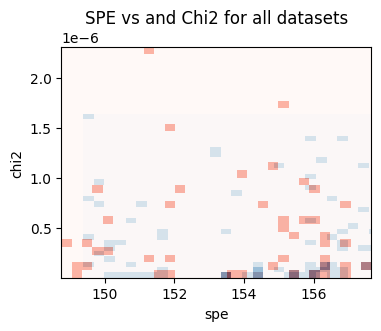

In [341]:
## checking spe and chi2 values
fig, ax = plt.subplots(1, 1, figsize=(4, 3))
ax.hist2d(speList, chi2List, bins=30, cmap='Blues', cmin = 0.0, alpha = 1.)

# # modify existing Reds colormap with a linearly fading alpha
# red = pl.cm.Reds  # original colormap
# fading_red = red(np.arange(red.N)) # extract colors
# fading_red[:, -1] = np.linspace(0, 1, red.N) # modify alpha
# fading_red = ListedColormap(fading_red) # convert to colormap

ax.hist2d(speListCo, chi2ListCo, bins=30, cmap="Reds", alpha = 0.5)
ax.set_title("SPE vs and Chi2 for all datasets")
ax.set_xlabel("spe")
ax.set_ylabel("chi2")

plt.show()

In [342]:
# pBatch1 = "/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput/"
pBatch1 = "/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput2_oct16/"

# 8 is the best fit right now
mc1 = MCdataSet(pBatch1+"10/")

# setup for physics comparisons
mc1.doCAcorrection_BinomialMC(config.get("mc_analysis").get("NCA"))
mc1.setup_forComparison(NBINS, BINLOW, BINHIGH)

# mc1.findRunByHeight(height = -1.0, key = "cob")

mc1.print()

mc1.check_physPars_andDetPars(verbose = 1);

['/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput2_oct16/10/Co57_ly_7000_h_1d5.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput2_oct16/10/Cs137_ly_7000_h_5d5_ly.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput2_oct16/10/Cs137_ly_7000_h_0d0_ly.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput2_oct16/10/Co57_ly_7000_h_4d0.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput2_oct16/10/Cs137_ly_7000_h_1d5_ly.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput2_oct16/10/Cs137_ly_7000_h_4d0_ly.root']
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput2_oct16/10/Co57_ly_7000_h_1d5.root
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput2_oct16/10/Cs137_ly_7000_h_5d5_ly.root
loaded in: 

In [343]:
comp1 = Comparator(realData)  # set it with real data
comp1.hScale = 32.0
# comp1.coBareMap = [None] * len(mc1.mCoBareList)
comp1.mMCDataSet = mc1  # set MC data/attributes

# print(mc1.findRunByHeight(0.0, key = "csb"))

# mc1.print()
comp1.do_mapping_fromJson("config.json")
comp1.print(mcVerb = 0, dataVerb= 0)

comp1.SetBinRanges(firstBin = FIRSTBIN) # set first bin as 1 and lastBin at 10 counts

# comp1.GuessOverallScaling() # set first guesses
print("full reduced off the bat (uses guess):", comp1.getFullReducedChi2())
print("or full reduced with guess explicit", comp1.getFullReducedChi2(useGuess=True)) 

print("Cs bare chi2", comp1.getCsBarechi2()) # use the guess because no scaling is passed
print("Co bare chi2", comp1.getCoBarechi2(), "\n") # use the guess because no scaling is passed


comp1.minimizeRateScaling(option = "CsBare", verbose = 0)
comp1.minimizeRateScaling(option = "CoBare", verbose = 0)

print("after minimizing", comp1.getFullReducedChi2())

# print("firstBin:", comp1.csBareMap[0].firstBin)
# print(f"\nCs scaleGuess: {comp1.csGuess:0.5f}")
# scalingX = np.linspace(comp1.csGuess/2., comp1.csGuess * 2., 4)
# [print(comp1.getCsBarechi2(scale)) for scale in scalingX]

# print(f"\nCo scaleGuess: {comp1.coGuess:0.4f}")
# # print(comp1.coBareMap[0].computeChi2_reduced(0.0137))
# scalingX = np.linspace(comp1.coGuess/4., comp1.coGuess * 2., 4)
# [print(comp1.getCoBarechi2(scale)) for scale in scalingX];


---- comparator.print() subcalls ----


---- COMPARATOR.print() ----
heights in pairMaps:
csBare: {1.5 : 1.5} {4.0 : 4.0} {5.5 : 5.5} 
coBare: {1.5 : 1.5} {4.0 : 4.0} 

full reduced off the bat (uses guess): 393.9331367961403
or full reduced with guess explicit 393.9331367961403
Cs bare chi2 13164.616000752754
Co bare chi2 2198.7763342967164 

after minimizing 392.4546684359314


firstBin: 0
/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput2_oct16/10/Cs137_ly_7000_h_1d5_ly.mac
392.4546684359314


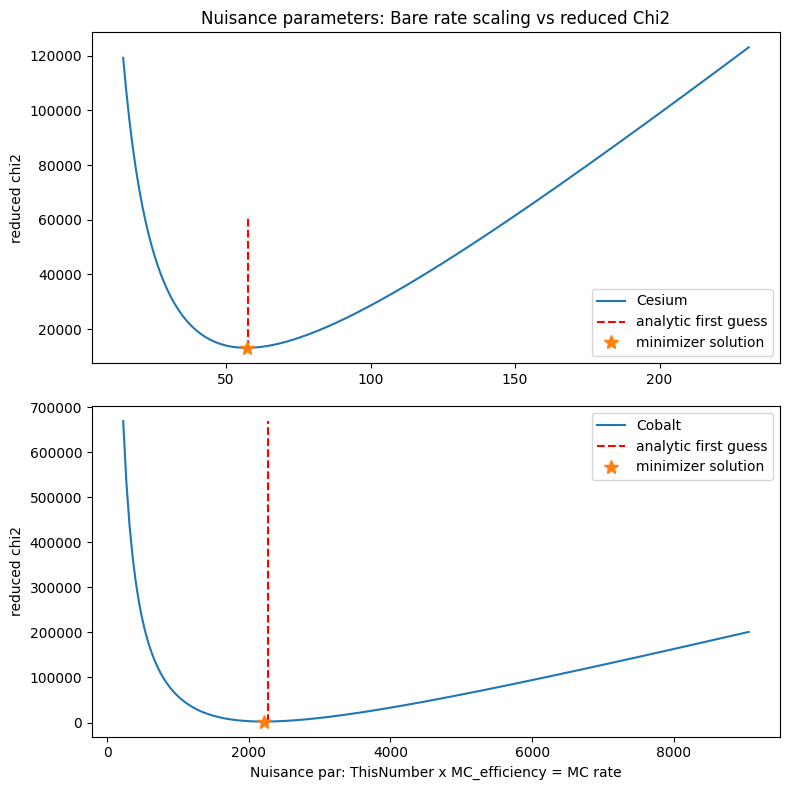

In [344]:
comp1.SetBinRanges(firstBin = 0) # set first bin as 1 and lastBin at 10 counts

## Cesium
# calculate the 1D space
scalingX_Cs = np.linspace(comp1.csGuess/4., comp1.csGuess * 4., 200)
chi2Full_Cs = np.array([comp1.getCsBarechi2(scale) for scale in scalingX_Cs])
comp1.minimizeRateScaling(option = "CsBare", verbose = 0)

print("firstBin:", comp1.csBareMap[2].firstBin)

## plot it
fig, (ax, ax2) = plt.subplots(2, 1, figsize = (8, 8))

ax.plot(scalingX_Cs, chi2Full_Cs, label = "Cesium")
ax.vlines(comp1.csGuess, min(chi2Full_Cs), max(chi2Full_Cs)/2, color = "r", linestyle = "--", label = "analytic first guess")
ax.plot(comp1.csBareNuis, comp1.getCsBarechi2(comp1.csBareNuis), linewidth = 0, marker= "*", markersize = 10, label = "minimizer solution")

ax.set_title("Nuisance parameters: Bare rate scaling vs reduced Chi2")
# ax.set_xlabel("Rate scaling (MCentries x This number / Nfired = MC rate) ")
ax.set_ylabel("reduced chi2")
ax.legend()

## Cobalt
scalingX_Co = np.linspace(comp1.coGuess/10., comp1.coGuess * 4., 200)
chi2Full_Co = np.array([comp1.getCoBarechi2(scale) for scale in scalingX_Co])
comp1.minimizeRateScaling(option = "CoBare", verbose = 0)

ax2.plot(scalingX_Co, chi2Full_Co, label = "Cobalt")
ax2.vlines(comp1.coGuess, min(chi2Full_Co), max(chi2Full_Co), color = "r", linestyle = "--", label = "analytic first guess")
ax2.plot(comp1.coBareNuis, comp1.getCoBarechi2(comp1.coBareNuis), linewidth = 0, marker= "*", markersize = 10, label = "minimizer solution")

ax2.set_xlabel("Nuisance par: ThisNumber x MC_efficiency = MC rate")
ax2.set_ylabel("reduced chi2")
ax2.legend()

print(comp1.csBareMap[0].mc.mRunPars.fname)
print(comp1.getFullReducedChi2())

plt.tight_layout()
plt.show()


/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput2_oct16/10/Cs137_ly_7000_h_1d5_ly.mac
392.4546684359314


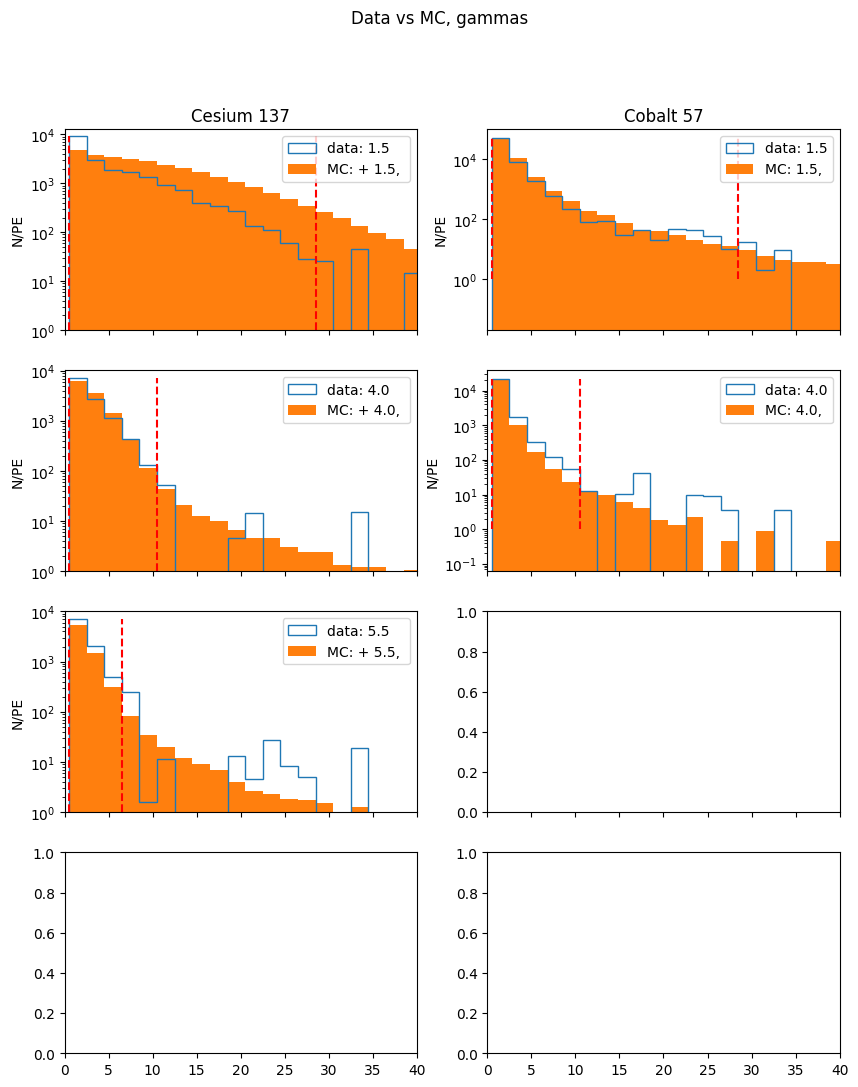

In [345]:
fig, axs = plt.subplots(4, 2, figsize = (10, 12), sharex=True)

# comp1.SetBinRanges(firstBin = FIRSTBIN) # set first bin as 1 and lastBin at 10 counts
comp1.csBareMap[0].GetMaxBin(comp1.csBareNuis)
# print(comp1.getFullReducedChi2())

comp1.SetBinRanges(firstBin = 0) # set first bin as 1 and lastBin at 10 counts
print(comp1.csBareMap[0].mc.mRunPars.fname)
print(comp1.getFullReducedChi2())

## cesium
axs[0, 0].set_title("Cesium 137")
for i, ax in enumerate(axs[:, 0].flat[0:len(comp1.csBareMap)]):
  pair = comp1.csBareMap[i]
  rc = pair.rc
  mc = pair.mc

  # s = f"""\n dataRaw: {rc.mBin_rawCounts[pair.lastBin]:0.1f}
  # \n mcRaw: {mc.mRaw_Counts[pair.lastBin]}
  # \n mc scaled: {mc.mRaw_Counts[pair.lastBin] * comp1.csBareNuis * rc.GetRunTime()}
  # """
  s = ""

  ax.hist(x = rc.mBinX, bins = rc.mBin_edges, weights = rc.mBin_rawCounts, histtype="step", label = "data: " + str(comp1.hScale - rc.mHeight))
  ax.hist(x = mc.mBinX, bins = mc.mBin_Edges, weights = mc.mRaw_Counts * comp1.csBareNuis * rc.GetRunTime() / mc.Nbeam, label = f"MC: + {str(mc.mRunPars.gammaHeight)}, {s}")

  maxVal = pair.GetMaxBin(comp1.csBareNuis)
  ax.vlines([rc.mBinX[pair.firstBin], rc.mBinX[pair.lastBin]], ymin =1, ymax = maxVal, color = "red", linestyle = "--")
  ax.set_yscale("log")
  ax.set_ylim(1, maxVal*1.4)
  ax.set_xlim(0, 40)
  ax.set_ylabel("N/PE")
  ax.legend()

axs[0, 1].set_title("Cobalt 57")
for i, ax in enumerate(axs[:, 1].flat[0:len(comp1.coBareMap)]):
  pair = comp1.coBareMap[i]
  rc = pair.rc
  mc = pair.mc

  # s = f"""\n dataRaw: {rc.mBin_rawCounts[pair.lastBin]:0.1f}
  # \n mcRaw: {mc.mRaw_Counts[pair.lastBin]}
  # \n mc scaled: {mc.mRaw_Counts[pair.lastBin] * comp1.coBareNuis * rc.GetRunTime()}
  # """
  ax.hist(x = rc.mBinX, bins = rc.mBin_edges, weights = rc.mBin_rawCounts, histtype="step", label = "data: " + str(comp1.hScale - rc.mHeight))
  ax.hist(x = mc.mBinX, bins = mc.mBin_Edges, weights = mc.mRaw_Counts * comp1.coBareNuis * rc.GetRunTime()/mc.Nbeam, label = f"MC: {str(mc.mRunPars.gammaHeight)}, {s}")

  maxVal = pair.GetMaxBin(comp1.coBareNuis)

  ax.vlines([rc.mBinX[pair.firstBin], rc.mBinX[pair.lastBin]], ymin =1, ymax = maxVal, color = "red", linestyle = "--")
  ax.set_yscale("log")
  # ax.set_ylim(1, maxVal*1.4)
  ax.set_ylabel("N/PE")
  ax.legend()

fig.suptitle("Data vs MC, gammas")
plt.show()

In [360]:
## check where we are MC stats limited
all_items = os.listdir(pBatch1)
folders = [item for item in all_items if os.path.isdir(os.path.join(pBatch1, item))]
folders = sorted(folders, key=lambda x: int(x))
# print("folders:", folders, "\n")

# toDo = []
# for folder in folders: # this is looping on phys pars
#   #open dataset
#   mcData = MCdataSet(pBatch1 + folder + "/", verbose = 0) # open dataset

#   # setup for physics comparisons
#   mcData.setup_forComparison(NBINS, BINLOW, BINHIGH, variable = "mNPE")
#   # 'mNPE_corrBinomial' var is used to match that generate by the correction call above
#   mcData.check_physPars_andDetPars(verbose = 0)

#   # do first sanity checks
#   comp1.mMCDataSet = mcData # point comp1 to mc data
#   comp1.do_mapping_fromJson(configName = "config.json")

#   stat = comp1.SetBinRanges(firstBin = 0, verbose = 0)
#   if isinstance(stat, list):
#     # print(stat)
#     [toDo.append(s) for s in stat];
# #   toDo.append(stat) if stat != 1 else None

[print('"',t, '", ', sep = "") for t in toDo]
print()

"/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput2_oct16/0/Co57_ly_2000_h_1d5.mac", 
"/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput2_oct16/0/Co57_ly_2000_h_4d0.mac", 
"/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput2_oct16/1/Co57_ly_2500_h_1d5.mac", 
"/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput2_oct16/1/Co57_ly_2500_h_4d0.mac", 
"/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput2_oct16/2/Co57_ly_3000_h_1d5.mac", 
"/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput2_oct16/2/Co57_ly_3000_h_4d0.mac", 
"/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput2_oct16/3/Co57_ly_3500_h_1d5.mac", 
"/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput2_oct16/4/Co57_ly_4000_h_1d5.mac", 
"/Users/austindestcroix/Desktop/school_holders/projects/

In [57]:
## doing the real fucking thing ##
# comp2 = Comparator(realData)  # set it with real data
GLOBALVERBOSE = 1

oldMethod = False

## loading in mc data forloop
# print(pBatch1)
all_items = os.listdir(pBatch1)
folders = [item for item in all_items if os.path.isdir(os.path.join(pBatch1, item))]
folders = sorted(folders, key=lambda x: int(x))
print("folders:", folders, "\n")
# break

firstBin_array = [0, 1, 2]
xLYs = [[] for _ in range(len(firstBin_array))]
yChi2s = [[] for _ in range(len(firstBin_array))]
yCoXs = [[] for _ in range(len(firstBin_array))]
yCsXs = [[] for _ in range(len(firstBin_array))]
zScalingCs = [[] for _ in range(len(firstBin_array))]
zScalingCo = [[] for _ in range(len(firstBin_array))]


for folder in folders: # this is looping on phys pars
  #open dataset
  mcData = MCdataSet(pBatch1 + folder + "/", verbose = 0) # open dataset based off existing root files

  # setup for physics comparisons
  mcData.doCAcorrection_BinomialMC(NCA)
  mcData.setup_forComparison(NBINS, BINLOW, BINHIGH, variable = "mNPE_corrBinomial")
  # 'mNPE_corrBinomial' var is used to match that generate by the correction call above
  mcData.check_physPars_andDetPars(verbose = 0)

  # do first sanity checks
  comp1.mMCDataSet = mcData # point comp1 to mc data
  comp1.do_mapping_fromJson(configName = "config.json")

  for pair in comp1.coBareMap:
    print("eff = ", pair.mc.eff, pair.mc.Nbeam)

  for iFirstBin in firstBin_array:
    verb = True if iFirstBin == 0 else False
    comp1.SetBinRanges(firstBin = iFirstBin, verbose = verb) # set first bin as 1 and lastBin at 10 counts. could do directly on MC object...

    if comp1.checkNDOF() == False: # if any NDOF are zero get false
      continue
    # comp1.GuessOverallScaling() # set first guesses
    
    # do minimizations of independent data sets
    status1, res1 = comp1.minimizeRateScaling(option = "CsBare")
    status2, res2 = comp1.minimizeRateScaling(option = "CoBare")
    comp1.getFullReducedChi2()
    
    ly = comp1.mMCDataSet.mCsBareList[0].mPhysPars.ly
    totalChi2 = comp1.totalRedChi2
    nuis = comp1.csBareNuis

    if GLOBALVERBOSE and verb:
      print("VERBOSE - folder:", folder, f"LY: {ly}, chi2 = {totalChi2}, iBin = {iFirstBin}")
      print(f"Cs: {comp1.csBareChi2:0f}, {comp1.csBareNuis:0.2f}")
      print(f"Co: {comp1.coBareChi2:0f}, {comp1.coBareNuis:0.2f}")
      print("chi2 = ", comp1.totalRedChi2, "\n")      

    # print(status1, status2)
    if status1 == 0 or status2 == 0:
      print("ERROR - folder:", folder, f"LY: {ly}, chi2 = {totalChi2}, nuis = {nuis}, iBin = {iFirstBin} \n")
      print("chi2 = ", comp1.getFullReducedChi2())  
      print(res1, res2)
    else:
      xLYs[iFirstBin].append(ly)
      yChi2s[iFirstBin].append(comp1.totalRedChi2)
      yCsXs[iFirstBin].append(comp1.csBareRedChi2)
      # print(comp1.csBareRedChi2)
      yCoXs[iFirstBin].append(comp1.coBareRedChi2)
      zScalingCs[iFirstBin].append(comp1.csBareNuis)
      zScalingCo[iFirstBin].append(comp1.coBareNuis)

comp1.print()

print("done building LY arrays")

folders: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16'] 

eff =  0.009914444444444444 18000000.0
eff =  0.0031026666666666668 18000000.0
YOO data limited in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput2_oct16/0/Co57_ly_2000_h_1d5.mac
   mc : data lastBin count =  7  :  46.90336857443424
VERBOSE - folder: 0 LY: 2000.0, chi2 = 1184.8907543581101, iBin = 0
Cs: 31907.335731, 94.42
Co: 8378.949917, 5420.18
chi2 =  1184.8907543581101 

eff =  0.011696944444444444 14400000.0
eff =  0.0038002083333333334 14400000.0
YOO data limited in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput2_oct16/1/Co57_ly_2500_h_1d5.mac
   mc : data lastBin count =  8  :  46.90336857443424
VERBOSE - folder: 1 LY: 2500.0, chi2 = 752.00930489004, iBin = 0
Cs: 20523.536215, 78.65
Co: 5044.780152, 4472.43
chi2 =  752.00930489004 

eff =  0.013240583333333333 12000000.0
eff =  0.004451 12000000.0
YOO data

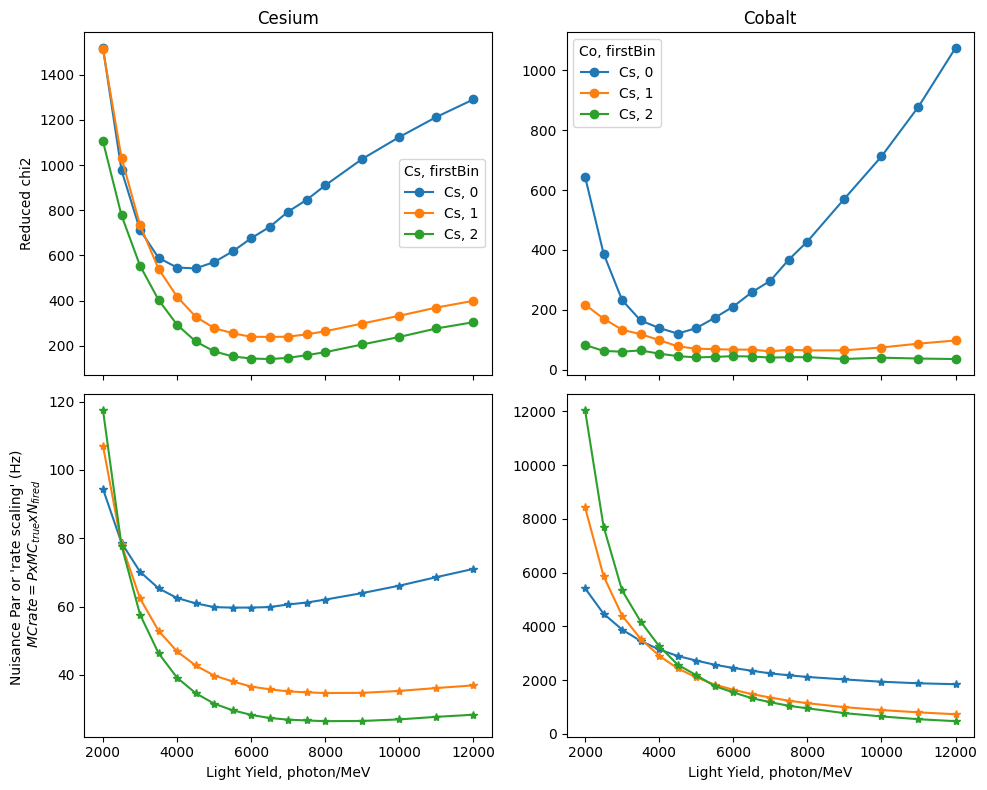

In [58]:
fig, ((ax1, ax3), (ax2, ax4)) = plt.subplots(2, 2, figsize = (10, 8), sharex = 'col')

for iBin in firstBin_array:
  ax1.plot(xLYs[iBin], yCsXs[iBin], linestyle = "-", marker = "o", label = f"Cs, {iBin}")
  ax2.plot(xLYs[iBin], zScalingCs[iBin], linestyle = "-", marker = "*", label = f"{iBin}")

ax1.legend(title="Cs, firstBin")
ax1.set_title("Cesium")
ax1.set_ylabel("Reduced chi2")
ax2.set_ylabel("Nuisance Par or 'rate scaling' (Hz) \n $MCrate = P x MC_{true} x N_{fired}$")
ax2.set_xlabel("Light Yield, photon/MeV")

for iBin in firstBin_array:
  ax3.plot(xLYs[iBin], yCoXs[iBin], linestyle = "-", marker = "o", label = f"Cs, {iBin}")
  ax4.plot(xLYs[iBin], zScalingCo[iBin], linestyle = "-", marker = "*", label = f"{iBin}")

ax3.set_title("Cobalt")
ax3.legend(title="Co, firstBin")
ax4.set_xlabel("Light Yield, photon/MeV")

# fig.suptitle("MC vs Data: Cs 137 - Bare SiPM")

plt.tight_layout()
plt.show()

348.0855012242363


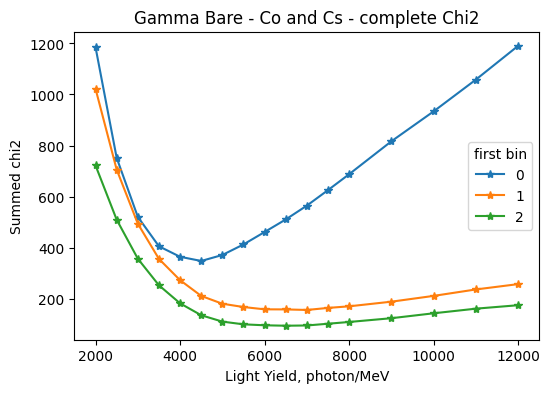

In [59]:
fig, ax = plt.subplots(1, 1, figsize = (6, 4))

for iBin in firstBin_array:
  ax.plot(xLYs[iBin], yChi2s[iBin], linestyle = "-", marker = "*", label = f"{iBin}")
  # ax2.plot(xLYs[iBin], zScalingCs[iBin], linestyle = "-", marker = "*")

print(min(yChi2s[0]))
ax.set_xlabel("Light Yield, photon/MeV")
ax.set_ylabel("Summed chi2")
ax.legend(title="first bin")
ax.set_title("Gamma Bare - Co and Cs - complete Chi2")
plt.show()